# **Notebook 2: Data Preparation**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `sampled_data.csv` — Created by Notebook 1
- [ ] `corporate_policies/` folder with `.md` SOP files
- [ ] Internet access (to download the tokenizer)

**Files this notebook will CREATE:**
- [ ] `./tokenized_train/`, `./tokenized_valid/`, `./tokenized_test/` — HuggingFace datasets _(Required by NB6)_
- [ ] `df_test.csv` — Test set with readable text + labels _(Required by NB5 and NB7)_

---

## **Stage 2: Data Preparation**
### **Task 2.1: Clean and Validate Dataset**

#### **2.1.1 Remove Duplicate and Invalid Records [2 marks]**
**The Task:** Identify and remove duplicate records using normalised deduplication (lowercase + strip before comparison), plus any invalid, incomplete, or corrupted records.

**Hints & Tips:**
* Load `sampled_data.csv` from Notebook 1 first.
* Normalised dedup: create a temporary `_norm` column = `instruction.str.lower().str.strip()`, drop duplicates on it, then drop the helper column.
* Check for nulls in `instruction`, `intent`, and `category` — drop rows missing any of these targets.
* Print the number of rows removed so the cleaning is auditable.

**Why we are doing it:** To prevent degraded training from redundant or broken records, and to stop near-duplicates leaking across train/test splits later.
**How we are doing it:** Pandas normalised deduplication and null filtering.

**Learner Inference:** Exact-match dedup misses `"Where is my order?"` vs `"where is my order?"`. Normalising first catches these and keeps your splits clean.

In [2]:
# YOUR CODE HERE
import pandas as pd

# Step 1: Load sampled_data.csv from Notebook 1
df = pd.read_csv("sampled_data.csv")
initial_count = len(df)

# Step 2: Drop rows missing target values in instruction, intent, or category
df = df.dropna(subset=["instruction", "intent", "category"]).copy()
after_null_count = len(df)

# Step 3: Create temporary normalised column (lowercase + strip)
df["_norm"] = df["instruction"].astype(str).str.lower().str.strip()

# Step 4: Drop duplicates on _norm and remove the temporary helper column
df = (
    df.drop_duplicates(subset=["_norm"])
    .drop(columns=["_norm"])
    .reset_index(drop=True)
)
final_count = len(df)

# Step 5: Print removed counts for an auditable cleaning summary
print(f"Initial rows: {initial_count}")
print(f"Removed (nulls in instruction/intent/category): {initial_count - after_null_count}")
print(f"Removed (normalised duplicates): {after_null_count - final_count}")
print(f"Remaining clean rows: {final_count}")

Initial rows: 3902
Removed (nulls in instruction/intent/category): 0
Removed (normalised duplicates): 0
Remaining clean rows: 3902


#### **2.1.2 Standardise Dataset Formatting [2 marks]**
**The Task:** Clean the strings inside `instruction`, `intent`, and `category` by stripping whitespace and enforcing uniform casing (intents = lower, categories = upper).

**Hints & Tips:**
* Use Pandas `.str.strip()`, `.str.lower()`, `.str.upper()`.
* Always strip whitespace BEFORE lowering — trailing spaces survive `.lower()`.
* Standardised casing prevents the model treating "Refund" and "refund" as different classes.

**Why we are doing it:** To ensure raw strings are perfectly standardised before injecting them into prompt templates.
**How we are doing it:** Pandas string manipulation.

**Learner Inference:** Standardising capitalisation prevents the model from treating the same intent written two ways as two separate classes.

In [3]:
# YOUR CODE HERE
# Strip leading/trailing whitespace first on all three columns
df["instruction"] = df["instruction"].astype(str).str.strip()
df["intent"] = df["intent"].astype(str).str.strip()
df["category"] = df["category"].astype(str).str.strip()

# Enforce uniform casing: intents in lowercase, categories in UPPERCASE
df["intent"] = df["intent"].str.lower()
df["category"] = df["category"].str.upper()

# Quick check of standardised values
print("Sample standardised rows:")
cols = ["instruction", "intent", "category"]
print(df[cols].head(10).to_markdown(index=True))

print("\nUnique Categories:")
for cat in df["category"].unique():
  print(f"- {cat}")

print("\nUnique Intents (first 10):")
for intent in df["intent"].unique()[:10]:
  print(f"- {intent}")

Sample standardised rows:
|    | instruction                                                | intent                   | category     |
|---:|:-----------------------------------------------------------|:-------------------------|:-------------|
|  0 | I can't talk with  a human agent                           | contact_human_agent      | CONTACT      |
|  1 | I have got to locate hte bills from {{Person Name}}        | check_invoice            | INVOICE      |
|  2 | I cannot pay, help me to inform of a problem with payments | payment_issue            | PAYMENT      |
|  3 | I want help speaking to customer service                   | contact_customer_service | CONTACT      |
|  4 | I try to see th accepted payment options                   | check_payment_methods    | PAYMENT      |
|  5 | where to sign up to the company nmewsletter                | newsletter_subscription  | SUBSCRIPTION |
|  6 | I'd like to see the withdrwaal fee how can i do it         | check_cancellation_fee   |

### **Task 2.2: Create Instruction-Tuning Dataset**

#### **2.2.1 Transform Records into Instruction Format [2 marks]**
**The Task:** Wrap the raw instructions and targets into a standardized `ChatML` format, forcing the assistant's response to be a strict JSON string containing the `intent` and `category`.

**Hints & Tips:**
* Use the Qwen tokenizer's `apply_chat_template(tokenize=False)`.
* The target JSON is `{"intent": "...", "category": "..."}` — built via `json.dumps()`.

**Model Selection:**
* **Qwen/Qwen2.5-1.5B-Instruct** (recommended) — fits T4, strong instruction following.
* **TinyLlama-1.1B-Chat** — lighter but weaker at structured output.
* **Llama-3-8B-Instruct** — best quality, needs >16GB VRAM even in 4-bit.
* Whatever you pick, set `MODEL_ID` here and in ALL later notebooks.

**Learner Inference:** Formatting the target as JSON establishes the exact structural rules the LoRA model learns to mimic in Stage 4.

In [4]:
# YOUR CODE HERE
import json
from transformers import AutoTokenizer

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

SYSTEM_PROMPT = (
    "You are a customer support classification assistant. "
    "Given a user instruction, respond strictly with a JSON object "
    "containing 'intent' and 'category'."
)


def format_chatml(row):
  target_json = json.dumps({
      "intent": row["intent"],
      "category": row["category"],
  })
  messages = [
      {"role": "system", "content": SYSTEM_PROMPT},
      {"role": "user", "content": row["instruction"]},
      {"role": "assistant", "content": target_json},
  ]
  return tokenizer.apply_chat_template(
      messages,
      tokenize=False,
      add_generation_prompt=False
  )

# Apply the function to create the 'text' column
df["text"] = df.apply(format_chatml, axis=1)

# Print the sample formatted ChatML record
print("Sample formatted ChatML record:\n")
print(df["text"].iloc[0])

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Sample formatted ChatML record:

<|im_start|>system
You are a customer support classification assistant. Given a user instruction, respond strictly with a JSON object containing 'intent' and 'category'.<|im_end|>
<|im_start|>user
I can't talk with  a human agent<|im_end|>
<|im_start|>assistant
{"intent": "contact_human_agent", "category": "CONTACT"}<|im_end|>



#### **2.2.2 Validate Instruction Templates [2 marks]**
**The Task:** Extract the assistant's portion of the generated ChatML string and parse it with `json.loads()` to verify structural integrity.

**Hints & Tips:**
* Split the string by `<|im_start|>assistant` and parse what follows.
* If this throws `JSONDecodeError`, your formatting in 2.2.1 is broken — fix before training.
* Validate several samples, not just the first.

**Learner Inference:** A JSONDecodeError here means the model would learn broken syntax. Catching it now saves a failed training run.

In [5]:
# YOUR CODE HERE
import json

valid_count = 0

for idx, text in enumerate(df["text"]):
    try:
        # 1. Split by <|im_start|>assistant to isolate the assistant's turn
        assistant_part = text.split("<|im_start|>assistant")[1]

        # 2. Remove the trailing <|im_end|> tag and strip surrounding whitespace
        json_str = assistant_part.split("<|im_end|>")[0].strip()

        # 3. Parse with json.loads() to verify valid JSON structure
        parsed_json = json.loads(json_str)

        # 4. Ensure both required keys exist
        assert "intent" in parsed_json and "category" in parsed_json
        valid_count += 1

    except Exception as e:
        raise ValueError(f"Validation failed at row {idx}: {e}\nRaw text:\n{text}")

print(f"Successfully validated {valid_count}/{len(df)} ChatML templates!")
print("Sample parsed JSON output:", json.loads(df["text"].iloc[0].split("<|im_start|>assistant")[1].split("<|im_end|>")[0].strip()))

Successfully validated 3902/3902 ChatML templates!
Sample parsed JSON output: {'intent': 'contact_human_agent', 'category': 'CONTACT'}


### **Task 2.3: Engineer Training and Retrieval Data**

#### **2.3.1 Tokenise Dataset [2 marks]**
**The Task:** Convert text sequences into tensor IDs and apply `-100` masking to padding tokens in the `labels` array.

**Hints & Tips:**
* If a token equals `tokenizer.pad_token_id`, replace it with `-100` in labels.
* `-100` is PyTorch's ignore index — the loss skips these tokens.

**Parameter Tuning:**
* `max_length`: `128` (fast, fits most Bitext prompts), `256` (safer if truncation seen), `64` (too aggressive).

**Learner Inference:** Masking isolates the loss — the model is penalised for wrong JSON, not for padding.

In [11]:
# YOUR CODE HERE
from datasets import Dataset

MAX_LEN = 128  # or 256 if longer sequences need extra room

# Ensure a pad token exists on the tokenizer
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

def tokenize_function(batch):
    enc = tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LEN,
        padding="max_length",
    )
    labels = [
        [-100 if token_id == tokenizer.pad_token_id else token_id for token_id in seq]
        for seq in enc["input_ids"]
    ]
    enc["labels"] = labels
    return enc

hf_dataset = Dataset.from_pandas(df[["text", "intent", "category"]])
tokenized_dataset = hf_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
print(tokenized_dataset)
for row in tokenized_dataset.select(range(3)):
  print(row)


Map:   0%|          | 0/3902 [00:00<?, ? examples/s]

Dataset({
    features: ['intent', 'category', 'input_ids', 'attention_mask', 'labels'],
    num_rows: 3902
})
{'intent': 'contact_human_agent', 'category': 'CONTACT', 'input_ids': [151644, 8948, 198, 2610, 525, 264, 6002, 1824, 23850, 17847, 13, 16246, 264, 1196, 7600, 11, 5889, 25470, 448, 264, 4718, 1633, 8482, 364, 56431, 6, 323, 364, 5471, 4427, 151645, 198, 151644, 872, 198, 40, 646, 944, 3061, 448, 220, 264, 3738, 8315, 151645, 198, 151644, 77091, 198, 4913, 56431, 788, 330, 6287, 86247, 25730, 497, 330, 5471, 788, 330, 73371, 9207, 151645, 198, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 1

#### **2.3.2 Analyse Token Distributions [2 marks]**
**The Task:** Analyse the token-count distribution to detect truncation risks and verify the sequence-length configuration.

**Hints & Tips:**
* Count non-padding tokens per row and plot a histogram.
* If >5% of rows hit `max_length`, increase it.
* The JSON target is ~20 tokens — if truncated, the model learns incomplete output.

**Learner Inference:** Sequences hitting the ceiling mean the JSON target is getting cut off, teaching the model to produce broken output.

Average token length: 66.2
Max token length observed: 78
Rows hitting MAX_LEN (128): 0/3902 (0.00%)
PASS: Truncation risk is under 5%. MAX_LEN = 128 is safe.


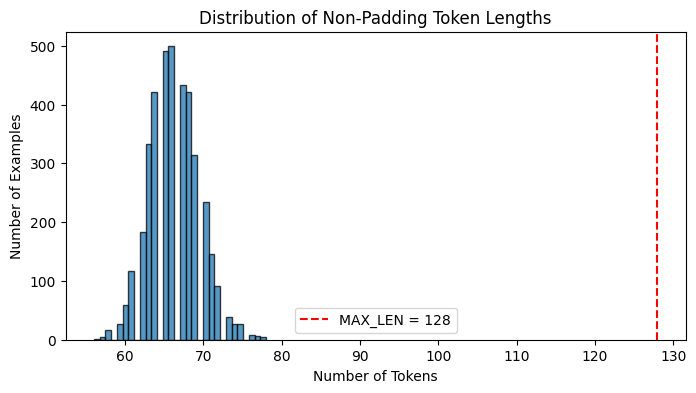

In [17]:
# YOUR CODE HERE
import numpy as np
import matplotlib.pyplot as plt

# 1. Count non-padding tokens per row using attention_mask (1 = real token, 0 = padding)
token_lengths = [sum(mask) for mask in tokenized_dataset["attention_mask"]]

# 2. Calculate summary statistics and truncation rate
max_observed = max(token_lengths)
mean_observed = np.mean(token_lengths)
truncated_count = sum(1 for length in token_lengths if length >= MAX_LEN)
truncated_pct = (truncated_count / len(token_lengths)) * 100

print(f"Average token length: {mean_observed:.1f}")
print(f"Max token length observed: {max_observed}")
print(f"Rows hitting MAX_LEN ({MAX_LEN}): {truncated_count}/{len(token_lengths)} ({truncated_pct:.2f}%)")

if truncated_pct > 5.0:
    print("WARNING: >5% of rows hit MAX_LEN. Increase MAX_LEN (e.g., to 256) in Task 2.3.1!")
else:
    print("PASS: Truncation risk is under 5%. MAX_LEN = 128 is safe.")

# 3. Plot histogram of token lengths
plt.figure(figsize=(8, 4))
plt.hist(token_lengths, bins=30, edgecolor="black", alpha=0.75)
plt.axvline(MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
plt.title("Distribution of Non-Padding Token Lengths")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Examples")
plt.legend()
plt.show()


#### **2.3.3 Prepare Retrieval Corpus [3 marks]**
**The Task:** Ingest the Markdown SOPs into LangChain Document objects ready to be embedded.

**Hints & Tips:**
* Use `TextLoader` from LangChain.
* Each `.md` file becomes one `Document` with `.page_content` and `.metadata`.
* These documents are embedded into ChromaDB in Notebook 4.

**Learner Inference:** These document objects form the knowledge base your bot retrieves from in Stages 3 and 4.

In [21]:
# Install necessary langchain packages first
#!pip install -q langchain langchain-community

import os
import glob
from langchain_community.document_loaders import TextLoader

# 1. Locate all Markdown (.md) SOP files inside the corporate_policies folder
md_files = sorted(glob.glob("corporate_policies/*.md"))

# 2. Load each .md file into a LangChain Document object
documents = []
for file_path in md_files:
    loader = TextLoader(file_path, encoding="utf-8")
    loaded_docs = loader.load()

    # Add clean filename metadata alongside the source path
    for doc in loaded_docs:
        doc.metadata["filename"] = os.path.basename(file_path)
    documents.extend(loaded_docs)

# 3. Verify the loaded corpus
print(f"Loaded {len(documents)} Markdown SOP documents:")
for doc in documents:
    print(f"- {doc.metadata['filename']} ({len(doc.page_content)} characters)")

# Preview the first document
if documents:
    print("\nSample metadata:", documents[0].metadata)
    print("Sample content preview:\n", documents[0].page_content[:500], "...")

Loaded 5 Markdown SOP documents:
- escalation_matrix.md (1550 characters)
- password_reset.md (1604 characters)
- refund_policy.md (1742 characters)
- shipping_delays.md (1542 characters)
- technical_troubleshooting.md (1646 characters)

Sample metadata: {'source': 'corporate_policies/escalation_matrix.md', 'filename': 'escalation_matrix.md'}
Sample content preview:
 # Escalation Matrix

## Purpose
Defines when and how to move a case beyond a first-line agent so customers
get the right authority quickly without unnecessary hand-offs.

## Severity Levels
- **P1 — Critical:** confirmed account takeover, payment fraud, data breach,
  or a widespread outage. Escalate immediately to the security or incident
  queue; do not wait for the customer to follow up.
- **P2 — High:** data loss risk, repeated failed resolution, high-value
  dispute, legal or regulatory men ...


### **Task 2.4: Create Dataset Partitions**

#### **2.4.1 Create Train, Validation, and Test Splits [5 marks]**
**The Task:** Split the tokenized dataset into Train (80%), Validation (10%), and Test (10%) partitions using stratified sampling. Demonstrate zero data leakage across all three.

**Hints & Tips:**
* Use `train_test_split` from sklearn with `stratify=df['intent']` so every intent appears in all splits.
* Split twice: first 80/20, then split the 20% into 50/50 (giving 10%/10%).
* The validation set is not optional — it is actively used during fine-tuning (Stage 4 / Notebook 6) for loss monitoring and early stopping.
* The test set must stay completely independent — used only for final evaluation.
* Verify zero overlap with set-intersection checks: `assert len(train_set & test_set) == 0`.
* Build a `df_test` DataFrame preserving readable `text`/`intent`/`category` columns for later scoring.

**Parameter Tuning:**
* Split ratio: `80/10/10` (recommended) or `70/15/15`. Any alternative must be justified.

**Why we are doing it:** To guarantee isolated, unseen data for unbiased evaluation, and a validation set for overfitting detection.
**How we are doing it:** Stratified sklearn splits with explicit programmatic leakage verification.

**Learner Inference:** Testing on data the model trained on gives false confidence (leakage). The held-out test split proves your model handles completely new phrasing; the validation split tells you when to stop training.

In [22]:
# YOUR CODE HERE
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Generate row indices and stratify labels
indices = np.arange(len(df))
intents = df["intent"].values

# 2. First split: 80% Train, 20% Temp (Validation + Test), stratified by intent
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=intents
)

# 3. Second split: Split the 20% Temp 50/50 into 10% Validation and 10% Test
valid_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=intents[temp_idx]
)

# 4. Slice the tokenized HuggingFace Dataset into Train, Valid, and Test partitions
tokenized_train = tokenized_dataset.select(train_idx)
tokenized_valid = tokenized_dataset.select(valid_idx)
tokenized_test = tokenized_dataset.select(test_idx)

# 5. Build readable df_test DataFrame for downstream scoring (NB5 & NB7)
df_test = df.iloc[test_idx][["instruction", "text", "intent", "category"]].reset_index(drop=True)

# 6. Verify split sizes, intent coverage, and zero data leakage
train_set = set(df.iloc[train_idx]["instruction"].str.lower().str.strip())
valid_set = set(df.iloc[valid_idx]["instruction"].str.lower().str.strip())
test_set = set(df.iloc[test_idx]["instruction"].str.lower().str.strip())

assert len(train_set & valid_set) == 0, "Leakage detected between Train and Valid!"
assert len(train_set & test_set) == 0, "Leakage detected between Train and Test!"
assert len(valid_set & test_set) == 0, "Leakage detected between Valid and Test!"

all_intents = set(df["intent"].unique())
assert set(df.iloc[train_idx]["intent"].unique()) == all_intents, "Missing intents in Train!"
assert set(df.iloc[valid_idx]["intent"].unique()) == all_intents, "Missing intents in Valid!"
assert set(df.iloc[test_idx]["intent"].unique()) == all_intents, "Missing intents in Test!"

print(f"Split Sizes -> Train: {len(tokenized_train)} (80%), Valid: {len(tokenized_valid)} (10%), Test: {len(tokenized_test)} (10%)")
print(f"Unique Intents -> Train: {len(set(tokenized_train['intent']))}, Valid: {len(set(tokenized_valid['intent']))}, Test: {len(set(tokenized_test['intent']))}")
print("PASS: Zero data leakage confirmed across all three partitions!")

Split Sizes -> Train: 3121 (80%), Valid: 390 (10%), Test: 391 (10%)
Unique Intents -> Train: 27, Valid: 27, Test: 27
PASS: Zero data leakage confirmed across all three partitions!


---
## Save Artifacts for Downstream Notebooks

**IMPORTANT:** These cells save all datasets. Notebooks 5, 6, and 7 depend on them.

In [23]:
# YOUR CODE HERE
import os

# 1. Save HuggingFace tokenized datasets to disk (required by NB6)
tokenized_train.save_to_disk("./tokenized_train")
tokenized_valid.save_to_disk("./tokenized_valid")
tokenized_test.save_to_disk("./tokenized_test")

# 2. Save readable test set to CSV (required by NB5 and NB7)
df_test.to_csv("df_test.csv", index=False)

# 3. Verify all saved artifacts exist on disk
expected_artifacts = [
    "./tokenized_train",
    "./tokenized_valid",
    "./tokenized_test",
    "df_test.csv"
]

for path in expected_artifacts:
    assert os.path.exists(path), f"Missing artifact: {path}"
    print(f"Saved and verified: {path}")

print("\nAll Notebook 2 artifacts are ready for downstream notebooks!")

Saving the dataset (0/1 shards):   0%|          | 0/3121 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/390 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/391 [00:00<?, ? examples/s]

Saved and verified: ./tokenized_train
Saved and verified: ./tokenized_valid
Saved and verified: ./tokenized_test
Saved and verified: df_test.csv

All Notebook 2 artifacts are ready for downstream notebooks!


In [24]:
import shutil
from google.colab import files

# 1. Zip the three tokenized folders into one archive
!zip -r tokenized_datasets.zip tokenized_train tokenized_valid tokenized_test

# 2. Download the zip archive and df_test.csv to your computer
files.download("tokenized_datasets.zip")
files.download("df_test.csv")

  adding: tokenized_train/ (stored 0%)
  adding: tokenized_train/dataset_info.json (deflated 71%)
  adding: tokenized_train/data-00000-of-00001.arrow (deflated 96%)
  adding: tokenized_train/state.json (deflated 38%)
  adding: tokenized_valid/ (stored 0%)
  adding: tokenized_valid/dataset_info.json (deflated 71%)
  adding: tokenized_valid/data-00000-of-00001.arrow (deflated 96%)
  adding: tokenized_valid/state.json (deflated 38%)
  adding: tokenized_test/ (stored 0%)
  adding: tokenized_test/dataset_info.json (deflated 71%)
  adding: tokenized_test/data-00000-of-00001.arrow (deflated 96%)
  adding: tokenized_test/state.json (deflated 38%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 3.**

- [ ] `sampled_data.csv` loaded
- [ ] **Duplicates + invalid records removed (normalised dedup)** ← _Task 2.1.1_
- [ ] Data standardised (intent=lower, category=UPPER)
- [ ] ChatML formatting applied and validated (valid JSON)
- [ ] Tokenization completed with `-100` label masking
- [ ] Token distribution analysed — truncation risk assessed
- [ ] Retrieval corpus loaded from `.md` files
- [ ] **Stratified Train/Valid/Test split** with all intents in every partition
- [ ] **Zero leakage verified** via set-intersection checks
- [ ] **`./tokenized_train/` + `./tokenized_valid/` saved** ← _CRITICAL for NB6_
- [ ] **`df_test.csv` saved** ← _CRITICAL for NB5 and NB7_

**If any item is unchecked, fix it before moving on.**